# Information Retrieval – Comparative Study of SMS Spam Classification

**Algorithms:** Decision Tree, KNN, SVM and Naïve Bayes

**Feature Extraction:** TF-IDF

**Dataset:** UCI SMS Spam Collection

In [84]:

import pandas as pd
import requests
import zipfile
import io

# Download the dataset
url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

response = requests.get(url)
response.raise_for_status()

# Extract the dataset
with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    with z.open("SMSSpamCollection") as file:
        df = pd.read_csv(
            file,
            sep="\t",
            header=None,
            names=["label", "message"]
        )

print("Dataset downloaded successfully!")


Dataset downloaded successfully!


In [85]:

# Display the first five messages
print(df.head())

# Display dataset dimensions
print("\nDataset Shape:")
print(df.shape)

# Count spam and ham messages
print("\nClass Distribution:")
print(df["label"].value_counts())


  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...

Dataset Shape:
(5572, 2)

Class Distribution:
label
ham     4825
spam     747
Name: count, dtype: int64


In [86]:

import re
import string
import nltk

from nltk.corpus import stopwords

nltk.download('stopwords')

print("Libraries imported successfully!")


Libraries imported successfully!


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [87]:

stop_words = set(stopwords.words('english'))

def clean_text(text):

    # Convert to lowercase
    text = text.lower()

    # Remove punctuation
    text = text.translate(str.maketrans('', '', string.punctuation))

    # Remove numbers
    text = re.sub(r'\d+', '', text)

    # Remove extra spaces
    text = text.strip()

    # Remove stop words
    words = text.split()
    words = [word for word in words if word not in stop_words]

    return " ".join(words)


# Test the function
sample = "FREE!!! Congratulations, YOU won a prize!!!"

print("Original:", sample)
print("Cleaned:", clean_text(sample))


Original: FREE!!! Congratulations, YOU won a prize!!!
Cleaned: free congratulations prize


In [88]:
print("Duplicate messages:", df["message"].duplicated().sum())

print("Messages with conflicting labels:",
      df.groupby("message")["label"].nunique().gt(1).sum())

Duplicate messages: 403
Messages with conflicting labels: 0


In [89]:
df = df.drop_duplicates(subset="message").copy()

print("Dataset after removing duplicates:", df.shape)
print(df["label"].value_counts())

Dataset after removing duplicates: (5169, 2)
label
ham     4516
spam     653
Name: count, dtype: int64


In [90]:
from sklearn.model_selection import train_test_split

df["cleaned_message"] = df["message"].apply(clean_text)

X_text = df["cleaned_message"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X_text,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))

Training messages: 4135
Testing messages: 1034


In [91]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(max_features=3000)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Training feature matrix:", X_train_tfidf.shape)
print("Testing feature matrix:", X_test_tfidf.shape)

Training feature matrix: (4135, 3000)
Testing feature matrix: (1034, 3000)


In [92]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": LinearSVC(random_state=42),
    "Naive Bayes": MultinomialNB()
}

for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    print(name, "trained successfully!")

Decision Tree trained successfully!
KNN trained successfully!
SVM trained successfully!
Naive Bayes trained successfully!


In [93]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = []

for name, model in models.items():

    y_pred = model.predict(X_test_tfidf)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, pos_label="spam")
    recall = recall_score(y_test, y_pred, pos_label="spam")
    f1 = f1_score(y_test, y_pred, pos_label="spam")

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

results_df = pd.DataFrame(results)

print(results_df.round(4))

           Model  Accuracy  Precision  Recall  F1 Score
0  Decision Tree    0.9545     0.8559  0.7710    0.8112
1            KNN    0.9072     0.9487  0.2824    0.4353
2            SVM    0.9758     0.9732  0.8321    0.8971
3    Naive Bayes    0.9729     1.0000  0.7863    0.8803


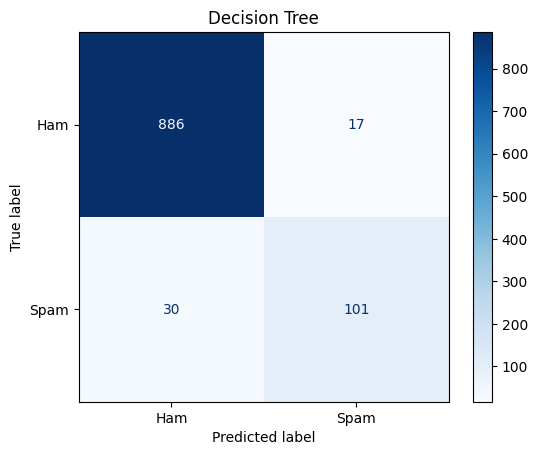

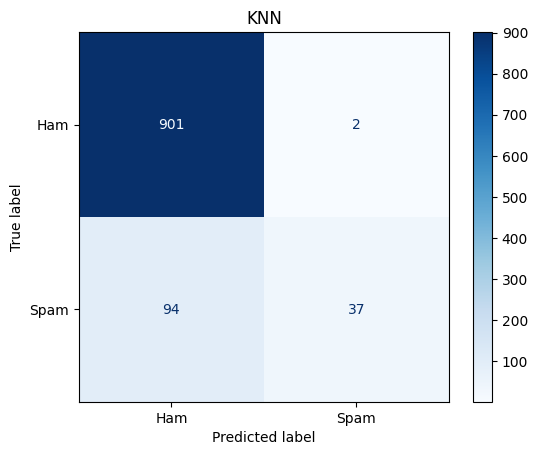

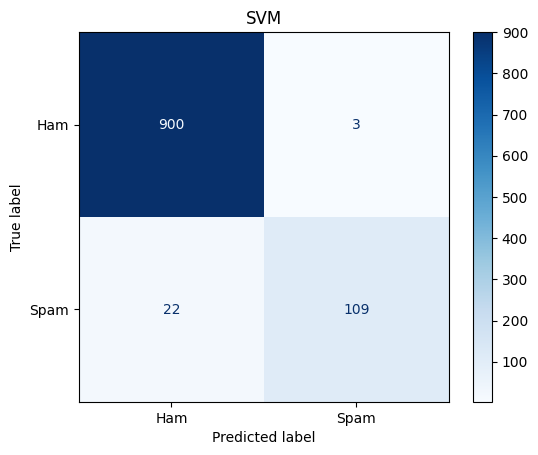

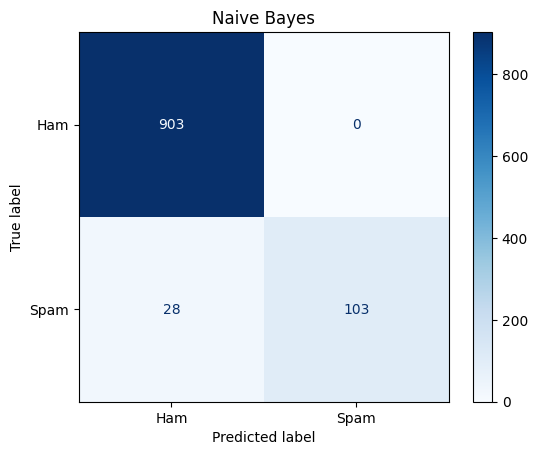

In [94]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

for name, model in models.items():
    y_pred = model.predict(X_test_tfidf)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=["ham", "spam"],
        display_labels=["Ham", "Spam"],
        cmap="Blues"
    )

    plt.title(name)
    plt.show()

### Confusion Matrix Analysis

Decision Tree missed 30 spam messages, while KNN missed 94. SVM missed only 22 spam messages and correctly detected 109. Naïve Bayes produced zero false alarms but missed 28 spam messages.

Overall, SVM performed best at detecting spam while maintaining a low number of false alarms.

KNN had lower spam recall, possibly because identifying similar messages using TF-IDF features can be difficult. SVM performed better at separating spam from ham, while Naïve Bayes was more conservative in predicting spam, resulting in fewer false alarms but more missed spam messages.

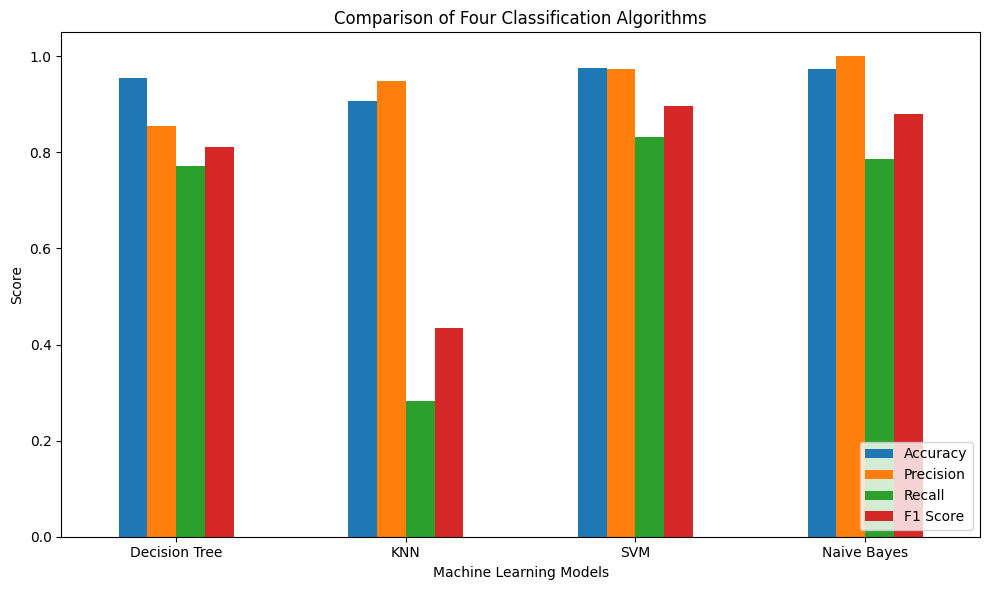

In [95]:
import matplotlib.pyplot as plt

metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Comparison of Four Classification Algorithms")
plt.ylabel("Score")
plt.xlabel("Machine Learning Models")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [96]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

vectorizer_5000 = TfidfVectorizer(max_features=5000)

X_train_5000 = vectorizer_5000.fit_transform(X_train)
X_test_5000 = vectorizer_5000.transform(X_test)

svm_5000 = LinearSVC(random_state=42)
svm_5000.fit(X_train_5000, y_train)

pred_5000 = svm_5000.predict(X_test_5000)

print("SVM with 5000 features")
print("Accuracy:", accuracy_score(y_test, pred_5000))
print("Precision:", precision_score(y_test, pred_5000, pos_label="spam"))
print("Recall:", recall_score(y_test, pred_5000, pos_label="spam"))
print("F1 Score:", f1_score(y_test, pred_5000, pos_label="spam"))

SVM with 5000 features
Accuracy: 0.9729206963249516
Precision: 0.9557522123893806
Recall: 0.8244274809160306
F1 Score: 0.8852459016393442


### What-if Experiment Analysis

The number of TF-IDF features was increased from 3,000 to 5,000 while keeping the same training and testing data. The results showed a slight decrease in accuracy and F1-score. Therefore, 3,000 features performed better in this experiment.

Dataset Distribution

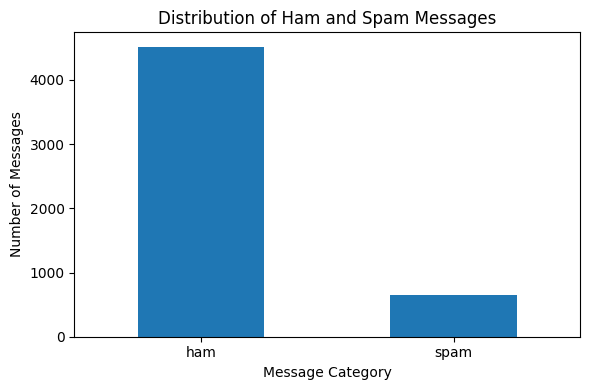

In [97]:
import matplotlib.pyplot as plt

df["label"].value_counts().plot(kind="bar", figsize=(6, 4))

plt.title("Distribution of Ham and Spam Messages")
plt.xlabel("Message Category")
plt.ylabel("Number of Messages")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

The graph shows that the dataset contains more Ham messages than Spam messages. This indicates class imbalance in the dataset.

### Conclusion

This project compared Decision Tree, KNN, SVM and Naïve Bayes for SMS spam classification using TF-IDF.

SVM achieved the best overall performance with 97.58% accuracy and an F1-score of 89.71%. Naïve Bayes achieved the highest precision, while KNN had the lowest recall.

In the what-if experiment, increasing TF-IDF features from 3,000 to 5,000 slightly reduced SVM's performance.

Therefore, SVM with 3,000 TF-IDF features is recommended for this dataset.
